  Account_ID Client_Name  Balance  Interest_Rate  Product_Type Account_Creation  Interest_Accrued
0       A101       Alice     5000          0.050       Savings       2026-01-15          0.684932
1       A102         Bob    12000          0.040  Term Deposit       2026-02-10          1.315068
2       A103     Charlie     8000          0.060       Savings       2025-12-20          1.315068
3       A104       Diana    15000          0.045  Term Deposit       2026-03-05          1.849315
4       A105       Ethan     3000          0.050       Savings       2026-01-25          0.410959
5       A106       Fiona    20000          0.030  Term Deposit       2026-02-28          1.643836
  Account_ID Client_Name  Balance  Interest_Rate  Product_Type  \
1       A102         Bob    12000          0.040  Term Deposit   
3       A104       Diana    15000          0.045  Term Deposit   
5       A106       Fiona    20000          0.030  Term Deposit   

  Account_Creation  Interest_Accrued  
1       20

/tmp/ipykernel_9505/2077243247.py:31: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_growth = df.resample("M", on="Account_Creation")["Balance"].sum()


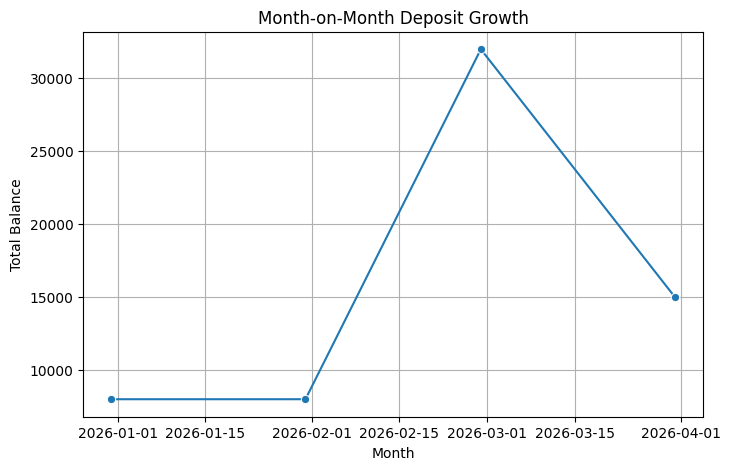

In [11]:
#Case Study 1 – Interest Computation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Account_ID": ["A101","A102","A103","A104","A105","A106"],
    "Client_Name": ["Alice","Bob","Charlie","Diana","Ethan","Fiona"],
    "Balance": [5000,12000,8000,15000,3000,20000],
    "Interest_Rate": [0.05,0.04,0.06,0.045,0.05,0.03],
    "Product_Type": ["Savings","Term Deposit","Savings","Term Deposit","Savings","Term Deposit"],
    "Account_Creation": ["2026-01-15","2026-02-10","2025-12-20","2026-03-05","2026-01-25","2026-02-28"]
}

df = pd.DataFrame(data)
df["Interest_Accrued"] = df["Balance"] * (df["Interest_Rate"] / 365)
print(df.to_string())


df["Account_Creation"] = pd.to_datetime(df["Account_Creation"])
promo_start = pd.Timestamp("2026-01-01")
promo_end = promo_start + pd.Timedelta(days=90)
term_deposit_clients = df[
    (df["Product_Type"] == "Term Deposit") &
    (df["Account_Creation"].between(promo_start, promo_end))
]
print(term_deposit_clients)


monthly_growth = df.resample("M", on="Account_Creation")["Balance"].sum()
plt.figure(figsize=(8,5))
sns.lineplot(x=monthly_growth.index, y=monthly_growth.values, marker="o")
plt.title("Month-on-Month Deposit Growth")
plt.xlabel("Month")
plt.ylabel("Total Balance")
plt.grid(True)
plt.show()




In [8]:
#Case Study 2: Customer Brokerage Management System

class BrokerageAccount:
    def __init__(self, account_id, client_name, balance):
        if balance < 0:
            raise ValueError("Initial deposit cannot be negative")
        self.account_id = account_id
        self.client_name = client_name
        self.balance = balance

    def calculate_fees(self, trade_amount):
        return trade_amount * 0.005

class PremiumAccount(BrokerageAccount):
    def calculate_fees(self, trade_amount):
        return trade_amount * 0.001

standard = BrokerageAccount("A101", "Alice", 5000)
premium = PremiumAccount("P202", "Bob", 10000)

print("Standard Account Fee:", standard.calculate_fees(2000))
print("Premium Account Fee:", premium.calculate_fees(2000))


Standard Account Fee: 10.0
Premium Account Fee: 2.0
